# M12.4.0 — Statistical contraction diagnostics

Unexecuted, validation-only observational analysis of M11, M12.1, M12.2 and M12.3-S1 on the identical 40,000 G1 rows. No training, inference, prediction correction, checkpoint selection, artifact writes, calibration, test or real-event evaluation.

**Question / predefined assessment:** Is contraction compatible with necessary moment properties of the conditional mean under the original G1 evaluation distribution? Inspect bias, residual orthogonality and reverse calibration jointly, with paired 95% bootstrap intervals. A slope below one alone is not a failure. Intervals excluding the appropriate zero/one reference indicate observed incompatibility conditional on the checkpoints and row-bootstrap assumptions, not proof of its cause. No automatic ranking, new acceptance threshold or scientific improvement claim.

M12.1/M12.2 weighting and M12.3 sampling change the effective training risk; their optimum need not be the original-distribution conditional mean. Diagnostics here use the same unweighted validation distribution for every model.

## Theory and exact sample algebra
For square-integrable $Y$, $m(X)=E[Y\mid X]$ minimizes population MSE. With $R=Y-m$, $E[R]=0$, $\operatorname{Cov}(Y,m)=\operatorname{Var}(m)$, $E[Rm]=0$, and $\mathrm{MSE}(m)=\operatorname{Var}(Y)-\operatorname{Var}(m)$. Thus slope($m$ on $Y$) equals $\operatorname{Var}(m)/\operatorname{Var}(Y)=1-\mathrm{MSE}(m)/\operatorname{Var}(Y)$; slope($Y$ on $m$) is one and its intercept zero when $\operatorname{Var}(m)>0$. Forward intercept is $E[Y](1-s)$, not generally zero.

For any predictor $F$, set $R=Y-F$ and use **denominator n for every variance/covariance**. Exactly, including finite samples,
$$\Delta_s=\frac{\operatorname{MSE}-\operatorname{Var}(Y)+\operatorname{Cov}(Y,F)}{\operatorname{Var}(Y)}
=\frac{\bar R^2-\operatorname{Cov}(R,F)}{\operatorname{Var}(Y)}
=\frac{\bar R^2-\overline{RF}+\bar R\bar F}{\operatorname{Var}(Y)}.$$
Consequently zero Delta_s can hide cancellation; it is **not a numerical estimate of Bayes excess risk**. Bias and orthogonality must be inspected separately. Necessary conditions are not sufficient: even a constant predictor equal to E[Y] passes several moments, with reverse slope undefined. Bayes excess risk requires the unknown m or additional experimental information.

Normalized residual orthogonality below means $\overline{RF}/\sqrt{\overline{R^2}\overline{F^2}}$ (uncentered, dimensionless). Also report centered $\operatorname{Cov}(R,F)/\operatorname{Var}(Y)$; raw orthogonality depends on the physical origin when residual bias is nonzero. Zero denominators produce NaN. Global bias follows the historical convention mean(F−Y); residual moments use R=Y−F.

## Inputs and provenance
The next two cells adapt M12_3_validation_evaluation's explicit paths and strict loader. Required: its four validation NPZs, four training JSONs, frozen M12.0 contract, G1 HDF5 (only labels, membership and validation final_network_snr read), split NPZ and train label-statistics NPZ. No waveform/embedding arrays or checkpoint tensors are loaded. Checkpoint filenames and embedded metadata are checked, not checkpoint-file content hashes.

**Units/schema:** the repository producer stores standardized `pred_val`/`y_val`, converted once with saved `y_mean`/`y_std` to physical units. This notebook uses these same archives, not newly generated physical copies. Literal physical-unit arrays under those keys are incompatible; resolve their producer/schema before running, never infer prediction units from ranges. Trusted NPZ object metadata uses allow_pickle=True. Missing inputs or mismatched provenance stop execution.

Data root uses src.paths. Review the explicit paths below before user-run execution. Only the small frozen contract and split/scaler are content-hashed; archive array hashes and metadata are recorded at runtime. Original row IDs are sorted independently and compared exactly. Frozen training CDF references are reconstructed from existing train labels and hash-checked, never fitted on validation. Runtime reads approximately 400,000×3 train labels, not strain data.


In [1]:
from pathlib import Path
import sys, json, hashlib, copy
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open from the cbc_pe repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
from src.models.evaluate import inverse_standardize
from src.models.sample_weighting import array_hash

CONFIG_PATHS = {"M11": ROOT / "configs/experiments/train_m11_final_G1_500k.json",
                "M12.1": ROOT / "configs/experiments/train_m12_1a_weighted_mse.json",
                "M12.2": ROOT / "configs/experiments/train_m12_2_marginal_alpha0p5.json",
                "M12.3-S1": ROOT / "configs/experiments/train_m12_3_S1_balanced_sampling.json"}
configs = {m:json.loads(p.read_text()) for m,p in CONFIG_PATHS.items()}
DATA_ROOT = resolve_data_root(config_data_root=configs["M11"].get("data_root"))
DATASET_ID = "M11_final_G1_500k"
LABELS = ["chirp_mass", "total_mass", "chi_eff"]
UNITS = ["Msun", "Msun", "dimensionless"]
MODELS = ["M11", "M12.1", "M12.2", "M12.3-S1"]
CANDIDATE = "M12.3-S1"
PAIRS = [(m,"M11") for m in MODELS[1:]] + [(CANDIDATE,"M12.1"),(CANDIDATE,"M12.2")]
PREFIX = {"M11":"M11", "M12.1":"M12_1", "M12.2":"M12_2", "M12.3-S1":"M12_3"}
REFERENCES = ["M11", "M12.1", "M12.2"]
RESULTS = DATA_ROOT / "results" / DATASET_ID

M12_1_VALIDATION_PATH = RESULTS / "m12_1_G1_val_predictions_embeddings.npz"
M12_2_VALIDATION_PATH = RESULTS / "m12_2_G1_val_predictions_embeddings.npz"  # Recorded in M12.2 evaluation; verify locally.
M12_3_VALIDATION_PATH = RESULTS / "m12_3_S1_G1_val_predictions_embeddings.npz"  # REQUIRED: actual future validation-only NPZ; no inference fallback.
BOOTSTRAP_COUNT = 400
BOOTSTRAP_SEED = 123
RUN_BOOTSTRAP = True  # Runs only when the user executes this notebook; 400 paired replicates.
MIN_COUNT = 30
MIN_2D_COUNT = 100
PERIPHERAL_MASS_MAX_DEGRADATION = 0.02  # Provisional, retained from the M12.2 evaluation configuration.
CHI_EFF_MAX_DEGRADATION = None  # RMSE fraction; decide prospectively, not after outcomes.
LOW_SNR_MAX_DEGRADATION = None  # RMSE fraction; decide prospectively, not after outcomes.

M11_VALIDATION_PATH = RESULTS / "m11_final_G1_500k_val_predictions_embeddings.npz"
CONTRACT_PATH = ROOT / "notebooks/m12/outputs/m12_0_baseline_contract.json"
PATHS = {key:resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
    file_name=configs["M11"]["dataset"][key], allow_legacy_flat=False)
    for key in ("dataset_file", "split_file", "label_stats_file")}

def require(ok, message):
    if not ok:
        raise ValueError(message)

def file_record(path, small=False):
    path = Path(path)
    require(path.is_file(), f"Missing frozen input: {path}; no generation fallback")
    st = path.stat()
    record = dict(path=str(path), size=st.st_size, mtime_ns=st.st_mtime_ns)
    if small:
        record["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return record

require(M12_3_VALIDATION_PATH is not None, "Set M12_3_VALIDATION_PATH after validation predictions are available")
def resolve_prediction_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else DATA_ROOT / path
prediction_paths = {"M11":M11_VALIDATION_PATH,
    "M12.1":resolve_prediction_path(M12_1_VALIDATION_PATH),
    "M12.2":resolve_prediction_path(M12_2_VALIDATION_PATH),
    CANDIDATE:resolve_prediction_path(M12_3_VALIDATION_PATH)}
require(len({p.resolve() for p in prediction_paths.values()}) == 4, "Prediction paths must be distinct")
for model, method, tag in (("M12.1","train_label_mahalanobis","M12_1"),
                           ("M12.2","train_label_marginal","M12_2")):
    expected = copy.deepcopy(configs["M11"])
    expected.pop("data_root", None)
    expected["training"]["sample_weighting"] = dict(method=method, alpha=.5, normalization="train_mean_one")
    expected["outputs"] = configs[model]["outputs"]
    actual = copy.deepcopy(configs[model]); actual.pop("data_root",None)
    require(actual == expected, f"{model}: unexpected scientific config differences")
    require(configs[model]["outputs"]["checkpoint_tag"].startswith(tag), "Wrong checkpoint tag")
expected = copy.deepcopy(configs["M11"]); expected.pop("data_root",None)
expected["training"]["balanced_sampling"] = dict(enabled=True,mode="marginal_mixture",
    threshold=.8,p_peripheral=.35,seed=123)
expected["outputs"] = configs[CANDIDATE]["outputs"]
actual = copy.deepcopy(configs[CANDIDATE]); actual.pop("data_root",None)
require(actual == expected, "M12.3-S1 differs from M11 beyond sampling/output tag")
require(actual["outputs"]["checkpoint_tag"].startswith("M12_3_S1_"), "Wrong sampling checkpoint tag")
# Use geometry/definitions only; historical test metrics and real-event results are not evaluated.
frozen = json.loads(CONTRACT_PATH.read_text())
require(frozen["schema_version"] == 1 and frozen["dataset_id"] == DATASET_ID
        and frozen["labels"] == LABELS, "Wrong M12.0 contract")
# Pin the small split/scaler contracts as well as train geometry; do not trust filenames alone.
for key in ("split_file", "label_stats_file"):
    require(file_record(PATHS[key], True)["sha256"] ==
            frozen["provenance"]["local_artifacts"][key]["sha256"],
            f"Frozen M12.0 artifact content mismatch: {key}")
geometry = frozen["geometry"]
P_EDGES = np.asarray(geometry["edges"], dtype=float)
SNR_EDGES = np.asarray(frozen["definitions"]["snr_edges"], dtype=float)
require(np.array_equal(P_EDGES, [0,20,40,60,80,100]), "Changed percentile bins")
require(np.array_equal(SNR_EDGES, [10,12.5,15,17.5,20,22.5,25]), "Changed SNR bins")
del frozen
provenance = dict(contract=file_record(CONTRACT_PATH, True),
    configs={m:file_record(p, True) for m,p in CONFIG_PATHS.items()},
    artifacts={k:file_record(p, k != "dataset_file") for k,p in PATHS.items()},
    predictions={m:file_record(p) for m,p in prediction_paths.items()},
    split="val", units=dict(zip(LABELS, UNITS)))


In [2]:
with np.load(PATHS["split_file"], allow_pickle=False) as z:
    train_ids = np.sort(z["train_idx"].copy())
    val_ids = np.sort(z["val_idx"].copy())
    require(int(z["seed"].item()) == 123, "Split seed changed")
for name, ids, n in (("train",train_ids,400000), ("val",val_ids,40000)):
    require(ids.shape == (n,) and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == n and ((ids >= 0) & (ids < 500000)).all(), f"Invalid {name} IDs")
require(np.intersect1d(train_ids, val_ids).size == 0, "Train/validation overlap")
require(array_hash(train_ids) == geometry["train_indices_sha256"], "Changed frozen train rows")
with np.load(PATHS["label_stats_file"], allow_pickle=False) as z:
    mean, std = z["y_mean"].copy(), z["y_std"].copy()
    require(z["label_names"].tolist() == LABELS, "Scaler label order")
    require(np.array_equal(np.sort(z["train_idx"]), train_ids), "Scaler train membership")
require(mean.shape == std.shape == (3,) and np.isfinite(mean).all()
        and np.isfinite(std).all() and (std > 0).all(), "Invalid saved scaler")

def load_validation(model):
    cfg = configs[model]
    checkpoint_name = (f"{DATASET_ID}_{cfg['model']['class_name']}_"
        f"{cfg['outputs']['checkpoint_tag']}_{cfg['training']['loss']}_seed123_checkpoint.pt")
    with np.load(prediction_paths[model], allow_pickle=True) as z:
        needed = {"pred_val", "y_val", "idx_val", "y_mean", "y_std", "label_names", "available_splits",
                  "checkpoint_file", "dataset_path", "split_path", "label_stats_path",
                  "model_config", "input_normalization"}
        require(needed <= set(z.files), f"{model}: missing {needed-set(z.files)}")
        require(z["available_splits"].tolist() == ["val"], "Require a validation-only prediction archive")
        require(z["label_names"].tolist() == LABELS, "Prediction label order")
        require(np.array_equal(z["y_mean"], mean) and np.array_equal(z["y_std"], std), "Scaler changed")
        saved = {k:z[k].item() for k in ("checkpoint_file", "dataset_path", "split_path",
                  "label_stats_path", "model_config", "input_normalization")}
        require(Path(saved["checkpoint_file"]).name == checkpoint_name, "Wrong recorded checkpoint")
        for key, local in (("dataset_path","dataset_file"), ("split_path","split_file"),
                           ("label_stats_path","label_stats_file")):
            require(Path(saved[key]).name == PATHS[local].name, "Recorded artifact mismatch")
        mc = saved["model_config"]
        require(mc["dataset_id"] == DATASET_ID and mc["label_names"] == LABELS, "Checkpoint dataset/labels")
        require(mc["class_name"] == cfg["model"]["class_name"]
                and mc["model_kwargs"] == cfg["model"]["kwargs"], "Checkpoint architecture changed")
        require(mc["training_seed"] == 123 and mc["split_seed"] == 123, "Checkpoint seeds changed")
        require(mc["train_size"] == 400000 and mc["val_size"] == 40000
                and mc["cal_size"] == 30000 and mc["test_size"] == 30000, "Checkpoint split sizes")
        require(saved["input_normalization"] == mc["input_normalization"] == cfg["input_normalization"],
                "Input normalization changed")
        require(mc["loss"] == cfg["training"]["loss"], "Checkpoint loss mismatch")
        if model == "M11":
            require(mc.get("sample_weighting") is None and not mc.get("balanced_sampling"),
                    "Baseline unexpectedly weighted or sampled")
        if model in ("M12.1", "M12.2"):
            w = mc["sample_weighting"]
            for key, value in cfg["training"]["sample_weighting"].items():
                require(w[key] == value, f"Weight provenance: {key}")
            for key in ("train_indices_sha256", "n_train"):
                require(w[key] == geometry[key], f"Training reference differs from M12.0: {key}")
            if model == "M12.1":
                for key in ("reference_distance_sha256", "rank"):
                    require(w[key] == geometry[key], f"Global reference mismatch: {key}")
            else:
                require(w["label_names"] == LABELS and w["normalization_axis"] == "independent per label",
                        "Marginal label order/normalization changed")
                require(w["reduction"] == "mean(weight * squared_error) over batch and labels",
                        "Marginal reduction changed")
                for key in ("reference_distance_sha256", "normalized_weight_sha256_per_label"):
                    require(set(w[key]) == set(LABELS), f"Incomplete marginal hashes: {key}")
                # Frozen marginal CDF verification follows below.
            require(w["validation_objective"] == "unweighted standardized MSELoss", "Weighted validation objective")
        if model == CANDIDATE:
            require(mc.get("sample_weighting") is None and mc["loss"] == "MSELoss",
                    "Sampling must use ordinary MSE without sample weighting")
            sampling = mc["balanced_sampling"]
            for key,value in dict(policy="M12.3-S1",mode="marginal_mixture",threshold=.8,
                                  p_peripheral=.35,seed=123,replacement=True,n_train=400000).items():
                require(sampling[key] == value, f"Sampling provenance mismatch: {key}")
            require(sampling["label_names"] == LABELS and
                    sampling["train_indices_sha256"] == geometry["train_indices_sha256"],
                    "Sampling labels/train rows mismatch")
            require(sampling["validation_objective"] == "unchanged unweighted standardized MSELoss",
                    "Sampling validation objective changed")
            require(sampling["seed_scheme"] ==
                    "SeedSequence([seed, 35, zero_based_epoch]); diagnostic S1 stream", "Sampling RNG contract")
        ids, truth_std, pred_std = (z[k].copy() for k in ("idx_val", "y_val", "pred_val"))
    require(ids.shape == val_ids.shape and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == len(ids), "Duplicate or malformed prediction IDs")
    require(np.array_equal(np.sort(ids), val_ids), "Prediction archive does not cover exact validation membership")
    require(truth_std.shape == pred_std.shape == (len(ids),3)
            and np.isfinite(truth_std).all() and np.isfinite(pred_std).all(), "Invalid predictions/targets")
    # Reindex each archive independently by original row ID, never zip raw rows.
    order = np.argsort(ids)
    truth_std, pred_std = truth_std[order], pred_std[order]
    provenance["predictions"][model].update(saved=saved, ordered_ids_sha256=array_hash(val_ids),
        truth_sha256=array_hash(truth_std), prediction_sha256=array_hash(pred_std))
    return dict(truth_std=truth_std,
        truth=inverse_standardize(truth_std.astype(np.float64), mean, std),
        pred=inverse_standardize(pred_std.astype(np.float64), mean, std))

loaded = {m:load_validation(m) for m in MODELS}
for model in MODELS[1:]:
    require(np.array_equal(loaded["M11"]["truth_std"], loaded[model]["truth_std"]),
            f"Paired truth mismatch: {model}")
y_true = loaded["M11"]["truth"]
predictions = {m:loaded[m]["pred"] for m in MODELS}

def read_rows(dataset, ids):
    result = np.empty((len(ids), *dataset.shape[1:]), dtype=np.float64)
    for start in range(0, len(ids), 4096):
        result[start:start+4096] = dataset[ids[start:start+4096]]
    return result

snr, snr_issue = None, None
with h5py.File(PATHS["dataset_file"], "r") as h:
    require(h.attrs.get("experiment_id") == DATASET_ID
            and h.attrs.get("labels") == ",".join(LABELS), "HDF5 identity/labels")
    require(h["y"].shape == (500000,3), "Wrong G1 label dimensions")
    membership = h["split"].asstr()[:]
    require(np.array_equal(np.flatnonzero(membership == "train"), train_ids)
            and np.array_equal(np.flatnonzero(membership == "val"), val_ids), "HDF5 split membership")
    physical_val = read_rows(h["y"], val_ids)
    require(np.allclose(physical_val, y_true, rtol=2e-6, atol=2e-5), "Physical units/row pairing mismatch")
    train_y = read_rows(h["y"], train_ids)
    if ("final_network_snr" in h and h.attrs.get("snr_low_frequency_cutoff") == 30.
            and h.attrs.get("snr_high_frequency_cutoff") == 512.):
        require(h["final_network_snr"].shape == (500000,), "Wrong SNR shape")
        snr = read_rows(h["final_network_snr"], val_ids)
        require(np.isfinite(snr).all() and (snr >= 0).all(), "Invalid SNR")
    else:
        snr_issue = "final_network_snr or 30–512 Hz definition unavailable; no replacement allowed"
del physical_val, membership, loaded
require(np.isfinite(train_y).all() and np.isfinite(y_true).all()
        and all(np.isfinite(p).all() for p in predictions.values()), "Nonfinite physical arrays")
residuals = {m:p-y_true for m,p in predictions.items()}
provenance["ordered_val_ids_sha256"] = array_hash(val_ids)
provenance["snr_status"] = snr_issue or "verified final_network_snr, optimal 30–512 Hz"
display(pd.DataFrame([dict(model=m, n=len(val_ids), checkpoint=provenance["predictions"][m]["saved"]["checkpoint_file"],
    ids_sha256=provenance["ordered_val_ids_sha256"]) for m in MODELS]))
require(snr is not None, "Required frozen SNR metadata unavailable: " + str(snr_issue))


,model,n,checkpoint,ids_sha256
0,M11,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
1,M12.1,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
2,M12.2,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
3,M12.3-S1,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...


## Frozen subset definitions
SNR uses final_network_snr (optimal network SNR, 30–512 Hz), edges [10,12.5,15,17.5,20,22.5,25], with explicit under/overflow. Marginal distance is |y−mu_train|/sigma_train and percentile is 100×fraction of train distances ≤ distance. Central pool <P80, peripheral ≥P80, central core ≤P50; these are distinct, overlapping diagnostics. Q10/Q90 are **train-only linear quantiles** with inclusive ties, unlike the validation-derived tail thresholds in the older evaluation notebook. They are fixed before bootstrap, never re-estimated on validation. No new reference artifact is saved.

Conditioning on SNR or label-defined regions changes the evaluation distribution. Label-selected tails can have systematic residual bias even for the true conditional mean; their moment failures do not directly refute global optimality. SNR might also contain information unavailable to the network. Subset diagnostics describe where behavior changes, not global conditional-mean tests.


In [3]:
mu = np.asarray(geometry["mean"], dtype=float)
sigma = np.asarray(geometry["std_ddof0"], dtype=float)
np.testing.assert_allclose(train_y.mean(axis=0), mu, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(train_y.std(axis=0), sigma, rtol=1e-12, atol=1e-12)
saved_marginal = provenance["predictions"]["M12.2"]["saved"]["model_config"]["sample_weighting"]
sampling_ref = provenance["predictions"][CANDIDATE]["saved"]["model_config"]["balanced_sampling"]["train_reference"]
for ref in (saved_marginal, sampling_ref):
    np.testing.assert_allclose(ref["mean"], mu, rtol=1e-12, atol=1e-12)
    np.testing.assert_allclose(ref["std_ddof0"], sigma, rtol=1e-12, atol=1e-12)
marginal_pct = np.empty_like(y_true)
for j, label in enumerate(LABELS):
    reference = np.sort(np.abs((train_y[:, j]-mu[j])/sigma[j]))
    for ref in (saved_marginal, sampling_ref):
        require(array_hash(reference) == ref["reference_distance_sha256"][label],
                f"Frozen marginal CDF mismatch: {label}")
    marginal_pct[:, j] = 100*np.searchsorted(reference,
        np.abs((y_true[:, j]-mu[j])/sigma[j]), side="right")/len(reference)
train_tail_thresholds = np.quantile(train_y, [.1, .9], axis=0, interpolation="linear")
display(pd.DataFrame(train_tail_thresholds.T, index=LABELS, columns=["train_Q10", "train_Q90"]))
scopes = {"global": (np.ones(len(val_ids), dtype=bool), list(range(3)))}
for b, (lo, hi) in enumerate(zip(SNR_EDGES[:-1], SNR_EDGES[1:])):
    mask = (snr >= lo) & ((snr <= hi) if b == len(SNR_EDGES)-2 else (snr < hi))
    scopes[f"SNR_{lo}_{hi}"] = (mask, list(range(3)))
scopes["SNR_below_10"] = (snr < 10, list(range(3)))
scopes["SNR_above_25"] = (snr > 25, list(range(3)))
require(np.all(np.sum([v[0] for k,v in scopes.items() if k.startswith("SNR_")], axis=0) == 1),
        "Incomplete SNR assignment")
for j, label in enumerate(LABELS):
    for name, mask in {
        "central_Plt80": marginal_pct[:,j] < 80,
        "central_core_Ple50": marginal_pct[:,j] <= 50,
        "peripheral_Pge80": marginal_pct[:,j] >= 80,
        "Q10_lower": y_true[:,j] <= train_tail_thresholds[0,j],
        "Q90_upper": y_true[:,j] >= train_tail_thresholds[1,j],
    }.items():
        scopes[label+"__"+name] = (mask, [j])
del train_y, reference


,train_Q10,train_Q90
chirp_mass,16.327675,61.049282
total_mass,47.967237,142.077261
chi_eff,-0.598997,0.598303


## Moment summaries and deterministic self-checks
The tiny discrete example checks the exact algebra for an arbitrary biased predictor. The Gaussian toy uses Y~N(2,4), X=Y+epsilon with epsilon~N(0,9), and m(X)=2+(4/13)(X−2). Its analytical moments are Var(m)=Cov(Y,m)=16/13 and MSE=36/13. A 4×4 product Gauss–Hermite quadrature integrates these polynomial Gaussian moments exactly (up to floating-point rounding), avoiding Monte Carlo tolerance choices. Quadrature weights are population expectations, not sample variance corrections. A deliberately shifted/rescaled predictor provides contrast; no correction is applied to any research prediction.


In [4]:
def moments(y, f, weights=None):
    y, f = np.asarray(y, dtype=np.float64), np.asarray(f, dtype=np.float64)
    avg = (lambda a: np.mean(a)) if weights is None else (lambda a: np.sum(weights*a))
    ym, fm = avg(y), avg(f)
    r = y-f
    vy, vf = avg((y-ym)**2), avg((f-fm)**2)
    cov = avg((y-ym)*(f-fm))
    mse, er, erf = avg(r*r), avg(r), avg(r*f)
    crf = avg((r-er)*(f-fm))
    div = lambda a,b: a/b if b > 0 else np.nan
    forward, reverse = div(cov,vy), div(cov,vf)
    target = 1-div(mse,vy)
    return dict(var_Y=vy, var_F=vf, cov_YF=cov, bias=fm-ym, MSE=mse,
        slope_F_on_Y=forward, intercept_F_on_Y=fm-forward*ym,
        slope_Y_on_F=reverse, intercept_Y_on_F=ym-reverse*fm,
        one_minus_MSE_over_varY=target, Delta_s=forward-target,
        cov_R_F=crf, mean_R_F=erf,
        normalized_orthogonality=div(erf,np.sqrt(mse*avg(f*f))),
        normalized_cov_R_F=div(crf,vy),
        algebra_rhs=div(er**2-crf,vy))

a = moments(np.array([-2., 0., 1., 4.]), np.array([1., 1., 2., 2.]))
np.testing.assert_allclose(a["Delta_s"], a["algebra_rhs"], atol=1e-14, rtol=1e-12)
from numpy.polynomial.hermite import hermgauss
nodes, w = hermgauss(4)
yg = np.broadcast_to(2+np.sqrt(8)*nodes[:,None], (4,4)).ravel()
eg = np.broadcast_to(np.sqrt(18)*nodes[None,:], (4,4)).ravel()
wg = (w[:,None]*w[None,:]/np.pi).ravel()
mg = 2+(4/13)*(yg+eg-2)
toy = pd.DataFrame({"posterior_mean": moments(yg,mg,wg),
                    "miscalibrated_0.6m_plus1": moments(yg,.6*mg+1,wg)}).T
np.testing.assert_allclose(toy.loc["posterior_mean", ["var_Y","var_F","cov_YF","MSE"]],
                           [4,16/13,16/13,36/13], atol=1e-12)
np.testing.assert_allclose(toy.loc["posterior_mean", ["bias","cov_R_F","mean_R_F","Delta_s",
                           "intercept_Y_on_F"]], 0, atol=1e-12)
np.testing.assert_allclose(toy.loc["posterior_mean", ["slope_F_on_Y","slope_Y_on_F"]],
                           [4/13,1], atol=1e-12)
np.testing.assert_allclose(toy.Delta_s, toy.algebra_rhs, atol=1e-12)
require(abs(toy.loc["miscalibrated_0.6m_plus1", "normalized_orthogonality"]) > .01,
        "Toy contrast should fail orthogonality")
display(toy)

rows = []
for scope, (mask, js) in scopes.items():
    for j in js:
        for model in MODELS:
            values = moments(y_true[mask,j], predictions[model][mask,j]) if mask.sum() >= MIN_COUNT else {}
            if values:
                np.testing.assert_allclose(values["Delta_s"], values["algebra_rhs"], atol=1e-12, rtol=1e-10)
            rows.append(dict(scope=scope, label=LABELS[j], model=model, n=int(mask.sum()),
                             supported=bool(mask.sum() >= MIN_COUNT), **values))
summary = pd.DataFrame(rows)
for label in LABELS:
    print(label, "physical units:", UNITS[LABELS.index(label)])
    display(summary[(summary.scope == "global") & (summary.label == label)].set_index("model"))


,var_Y,var_F,cov_YF,bias,MSE,slope_F_on_Y,intercept_F_on_Y,slope_Y_on_F,intercept_Y_on_F,one_minus_MSE_over_varY,Delta_s,cov_R_F,mean_R_F,normalized_orthogonality,normalized_cov_R_F,algebra_rhs
posterior_mean,4.0,1.230769,1.230769,4.440892e-16,2.769231,0.307692,1.384615,1.000000,-1.332268e-15,0.307692,1.665335e-16,2.359224e-16,2.220446e-16,5.834154e-17,5.898060e-17,-5.898060e-17
miscalibrated_0.6m_plus1,4.0,0.443077,0.738462,2.000000e-01,3.006154,0.184615,1.830769,1.666667,-1.666667e+00,0.248462,-6.384615e-02,2.953846e-01,-1.446154e-01,-3.628820e-02,7.384615e-02,-6.384615e-02


chirp_mass physical units: Msun


,scope,label,n,supported,var_Y,var_F,cov_YF,bias,MSE,slope_F_on_Y,intercept_F_on_Y,slope_Y_on_F,intercept_Y_on_F,one_minus_MSE_over_varY,Delta_s,cov_R_F,mean_R_F,normalized_orthogonality,normalized_cov_R_F,algebra_rhs
model,,,,,,,,,,,,,,,,,,,,
M11,global,chirp_mass,40000,True,272.750317,216.772386,227.785431,0.078911,33.958069,0.835143,6.239254,1.050805,-1.981374,0.875498,-0.040355,11.013044,8.058101,0.034366,0.040378,-0.040355
M12.1,global,chirp_mass,40000,True,272.750317,225.529705,232.436313,0.447505,33.607656,0.852194,5.970662,1.030624,-1.605556,0.876782,-0.024588,6.906608,-10.015889,-0.042462,0.025322,-0.024588
M12.2,global,chirp_mass,40000,True,272.750317,230.436295,234.784471,0.059430,33.621203,0.860804,5.260881,1.018869,-0.765655,0.876733,-0.015929,4.348175,2.123873,0.009069,0.015942,-0.015929
M12.3-S1,global,chirp_mass,40000,True,272.750317,235.668916,236.976282,0.086706,34.474187,0.868840,4.987872,1.005547,-0.294483,0.873605,-0.004766,1.307366,-1.940163,-0.008163,0.004793,-0.004766


total_mass physical units: Msun


,scope,label,n,supported,var_Y,var_F,cov_YF,bias,MSE,slope_F_on_Y,intercept_F_on_Y,slope_Y_on_F,intercept_Y_on_F,one_minus_MSE_over_varY,Delta_s,cov_R_F,mean_R_F,normalized_orthogonality,normalized_cov_R_F,algebra_rhs
model,,,,,,,,,,,,,,,,,,,,
M11,global,total_mass,40000,True,1203.703658,977.201918,1034.369523,0.379522,112.310568,0.859322,13.720368,1.058501,-5.949567,0.906696,-0.047373,57.167605,21.032421,0.019804,0.047493,-0.047373
M12.1,global,total_mass,40000,True,1203.703658,1021.061645,1058.178508,1.280246,110.047316,0.879102,12.745321,1.036351,-4.774074,0.908576,-0.029474,37.116863,-85.931455,-0.080875,0.030836,-0.029474
M12.2,global,total_mass,40000,True,1203.703658,1010.167495,1051.978378,0.718519,110.430668,0.873951,12.672066,1.041390,-4.673392,0.908258,-0.034306,41.810882,-26.844543,-0.025368,0.034735,-0.034306
M12.3-S1,global,total_mass,40000,True,1203.703658,1072.751264,1082.089661,-0.528992,112.555434,0.898967,9.052263,1.008705,-0.291930,0.906492,-0.007526,9.338396,59.224383,0.055919,0.007758,-0.007526


chi_eff physical units: dimensionless


,scope,label,n,supported,var_Y,var_F,cov_YF,bias,MSE,slope_F_on_Y,intercept_F_on_Y,slope_Y_on_F,intercept_Y_on_F,one_minus_MSE_over_varY,Delta_s,cov_R_F,mean_R_F,normalized_orthogonality,normalized_cov_R_F,algebra_rhs
model,,,,,,,,,,,,,,,,,,,,
M11,global,chi_eff,40000,True,0.192717,0.144118,0.149550,-0.005354,0.037764,0.776008,-0.005369,1.037688,0.005559,0.804043,-0.028035,0.005432,0.005403,0.073224,0.028184,-0.028035
M12.1,global,chi_eff,40000,True,0.192717,0.145903,0.150464,-0.002470,0.037699,0.780751,-0.002484,1.031257,0.002549,0.804383,-0.023632,0.004560,0.004554,0.061405,0.023664,-0.023632
M12.2,global,chi_eff,40000,True,0.192717,0.148051,0.151230,0.004016,0.038324,0.784726,0.004003,1.021471,-0.004101,0.801137,-0.016411,0.003179,0.003163,0.041989,0.016495,-0.016411
M12.3-S1,global,chi_eff,40000,True,0.192717,0.162328,0.158066,0.007704,0.038972,0.820199,0.007692,0.973745,-0.007503,0.797776,0.022423,-0.004262,-0.004321,-0.054314,-0.022115,0.022423


## Paired uncertainty, including subset counts
400 replicates, RNG seed 123; global resamples select positions in the identical sorted 40,000-ID vector for all four models. Each fixed subset is resampled separately within its n rows, with shared draws for all models (matching the earlier region-bootstrap convention). Only one replicate of rows is materialized at a time. Subset membership and train thresholds remain fixed. n<30 retains counts but metrics/intervals are undefined.

Report per-model intervals and candidate−reference contrasts for Delta_s, uncentered/centered residual orthogonality, forward/reverse slopes, reverse intercept and bias. Quantiles are 2.5/97.5 percentiles; valid/invalid replicate counts are explicit. Nulls: zero for bias/orthogonality/Delta_s/reverse intercept, one for reverse slope; forward slope has no universal unit-slope null. Differences of signed diagnostics have no universal favorable direction.

These are marginal, exploratory intervals with no multiplicity correction. IID validation rows are assumed; possible shared-source dependence is unresolved. These validation-selected checkpoints are treated as fixed, so intervals omit selection and training-seed uncertainty and are not untouched-test inference. Passing moments cannot prove Bayes optimality or intrinsic identifiability.


In [5]:
BOOT_METRICS = ["Delta_s", "normalized_orthogonality", "normalized_cov_R_F",
                "slope_F_on_Y", "slope_Y_on_F", "intercept_Y_on_F", "bias"]
bootstrap_rows = []
if RUN_BOOTSTRAP:
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    for scope, (mask, js) in scopes.items():
        positions = np.flatnonzero(mask)
        if len(positions) < MIN_COUNT:
            continue
        samples = np.full((BOOTSTRAP_COUNT,len(MODELS),len(js),len(BOOT_METRICS)), np.nan)
        for b in range(BOOTSTRAP_COUNT):
            draw = rng.choice(positions, size=len(positions), replace=True)
            for mi, model in enumerate(MODELS):
                for ji, j in enumerate(js):
                    values = moments(y_true[draw,j], predictions[model][draw,j])
                    samples[b,mi,ji] = [values[k] for k in BOOT_METRICS]
        contrasts = [(m, None) for m in MODELS] + PAIRS
        for candidate, ref in contrasts:
            draws = samples[:,MODELS.index(candidate)].copy()
            if ref is not None:
                draws -= samples[:,MODELS.index(ref)]
            for ji,j in enumerate(js):
                point = summary[(summary.scope == scope) & (summary.label == LABELS[j])].set_index("model")
                for ki,metric in enumerate(BOOT_METRICS):
                    valid = draws[:,ji,ki][np.isfinite(draws[:,ji,ki])]
                    lo,hi = np.percentile(valid,[2.5,97.5]) if len(valid) >= .95*BOOTSTRAP_COUNT else (np.nan,np.nan)
                    estimate = point.loc[candidate,metric]-(point.loc[ref,metric] if ref else 0)
                    bootstrap_rows.append(dict(scope=scope,label=LABELS[j], candidate=candidate,
                        reference=ref or "absolute",metric=metric,n=len(positions), estimate=estimate,
                        ci_low=lo,ci_high=hi,valid_replicates=len(valid),
                        invalid_replicates=BOOTSTRAP_COUNT-len(valid)))
bootstrap = pd.DataFrame(bootstrap_rows)
if not bootstrap.empty:
    display(bootstrap[bootstrap.scope == "global"])
else:
    print("Bootstrap disabled: uncertainty unresolved.")
# Complete conditional tables remain available in memory, with counts and uncertainty.
display(summary[summary.scope != "global"])
if not bootstrap.empty:
    display(bootstrap[bootstrap.scope != "global"])


,scope,label,candidate,reference,metric,n,estimate,ci_low,ci_high,valid_replicates,invalid_replicates
0,global,chirp_mass,M11,absolute,Delta_s,40000,-0.040355,-0.042875,-0.037873,400,0
1,global,chirp_mass,M11,absolute,normalized_orthogonality,40000,0.034366,0.023791,0.044867,400,0
2,global,chirp_mass,M11,absolute,normalized_cov_R_F,40000,0.040378,0.037931,0.042913,400,0
3,global,chirp_mass,M11,absolute,slope_F_on_Y,40000,0.835143,0.832317,0.838127,400,0
4,global,chirp_mass,M11,absolute,slope_Y_on_F,40000,1.050805,1.047530,1.054180,400,0
...,...,...,...,...,...,...,...,...,...,...,...
184,global,chi_eff,M12.3-S1,M12.2,normalized_cov_R_F,40000,-0.038610,-0.040519,-0.036958,400,0
185,global,chi_eff,M12.3-S1,M12.2,slope_F_on_Y,40000,0.035473,0.033538,0.037457,400,0
186,global,chi_eff,M12.3-S1,M12.2,slope_Y_on_F,40000,-0.047727,-0.050140,-0.045536,400,0
187,global,chi_eff,M12.3-S1,M12.2,intercept_Y_on_F,40000,-0.003402,-0.004245,-0.002396,400,0


,scope,label,model,n,supported,var_Y,var_F,cov_YF,bias,MSE,...,intercept_F_on_Y,slope_Y_on_F,intercept_Y_on_F,one_minus_MSE_over_varY,Delta_s,cov_R_F,mean_R_F,normalized_orthogonality,normalized_cov_R_F,algebra_rhs
12,SNR_10.0_12.5,chirp_mass,M11,6757,True,270.848340,190.750854,199.206164,-0.103070,63.197491,...,9.721272,1.044326,-1.538717,0.766668,-0.031179,8.455309,12.272889,0.039055,0.031218,-0.031179
13,SNR_10.0_12.5,chirp_mass,M12.1,6757,True,270.848340,201.240270,205.151978,0.458115,61.994523,...,9.467104,1.019438,-1.188978,0.771110,-0.013668,3.911708,-13.313281,-0.042075,0.014442,-0.013668
14,SNR_10.0_12.5,chirp_mass,M12.2,6757,True,270.848340,212.095884,210.482101,0.045260,61.982072,...,8.323325,0.992391,0.237686,0.771156,0.005966,-1.613784,-3.296863,-0.010486,-0.005958,0.005966
15,SNR_10.0_12.5,chirp_mass,M12.3-S1,6757,True,270.848340,214.602093,211.522757,0.199272,62.444628,...,8.334632,0.985651,0.336534,0.769448,0.011516,-3.079335,-10.520333,-0.033190,-0.011369,0.011516
16,SNR_10.0_12.5,total_mass,M11,6757,True,1211.724786,891.783232,939.559228,0.101152,224.399794,...,21.193785,1.053574,-5.137545,0.814810,-0.039420,47.775996,38.266773,0.025898,0.039428,-0.039420
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,chi_eff__Q10_lower,chi_eff,M12.3-S1,3890,True,0.008881,0.031788,0.002938,0.179664,0.067071,...,-0.313375,0.092438,-0.685339,-6.552454,6.883331,-0.028849,0.071256,0.470315,-3.248573,6.883331
164,chi_eff__Q90_upper,chi_eff,M11,3951,True,0.009051,0.027230,0.005517,-0.171540,0.054673,...,0.115566,0.202602,0.621099,-5.040791,5.650343,-0.021713,0.074998,0.546016,-2.399072,5.650343
165,chi_eff__Q90_upper,chi_eff,M12.1,3951,True,0.009051,0.027393,0.005735,-0.162551,0.051397,...,0.106858,0.209349,0.615413,-4.678830,5.312448,-0.021658,0.071447,0.528590,-2.392987,5.312448
166,chi_eff__Q90_upper,chi_eff,M12.2,3951,True,0.009051,0.024908,0.005347,-0.162513,0.049675,...,0.138390,0.214666,0.612360,-4.488642,5.079430,-0.019561,0.073528,0.555240,-2.161338,5.079430


,scope,label,candidate,reference,metric,n,estimate,ci_low,ci_high,valid_replicates,invalid_replicates
189,SNR_10.0_12.5,chirp_mass,M11,absolute,Delta_s,6757,-0.031179,-0.039689,-0.023216,400,0
190,SNR_10.0_12.5,chirp_mass,M11,absolute,normalized_orthogonality,6757,0.039055,0.012064,0.064784,400,0
191,SNR_10.0_12.5,chirp_mass,M11,absolute,normalized_cov_R_F,6757,0.031218,0.023285,0.039770,400,0
192,SNR_10.0_12.5,chirp_mass,M11,absolute,slope_F_on_Y,6757,0.735490,0.724470,0.745485,400,0
193,SNR_10.0_12.5,chirp_mass,M11,absolute,slope_Y_on_F,6757,1.044326,1.032433,1.057714,400,0
...,...,...,...,...,...,...,...,...,...,...,...
2263,chi_eff__Q90_upper,chi_eff,M12.3-S1,M12.2,normalized_cov_R_F,3951,-0.298992,-0.472471,-0.125017,400,0
2264,chi_eff__Q90_upper,chi_eff,M12.3-S1,M12.2,slope_F_on_Y,3951,0.009791,-0.017612,0.038516,400,0
2265,chi_eff__Q90_upper,chi_eff,M12.3-S1,M12.2,slope_Y_on_F,3951,-0.018457,-0.034411,-0.003698,400,0
2266,chi_eff__Q90_upper,chi_eff,M12.3-S1,M12.2,intercept_Y_on_F,3951,0.004380,-0.004428,0.013987,400,0


## Two figures: forward contraction and reverse calibration
Scatter uses one deterministic subset of at most 1,500 common row IDs. Lines and calibration bin means use all 40,000 rows. Forward reference includes identity, fitted OLS, and the hypothetical necessary-condition slope 1−MSE/Var(Y), anchored at (mean Y, mean Y); this is not a fitted Bayes predictor. Reverse panels bin F into ten empirical quantile bins for visualization only, plotting mean Y against mean F, with identity and reverse OLS. Duplicate edges are collapsed. Error bars are descriptive ±1.96 standard errors of Y within the fixed bins, not simultaneous or checkpoint-selection-adjusted intervals. Counts are displayed separately; unsupported bins are omitted. These prediction bins are not training references and do not modify predictions.


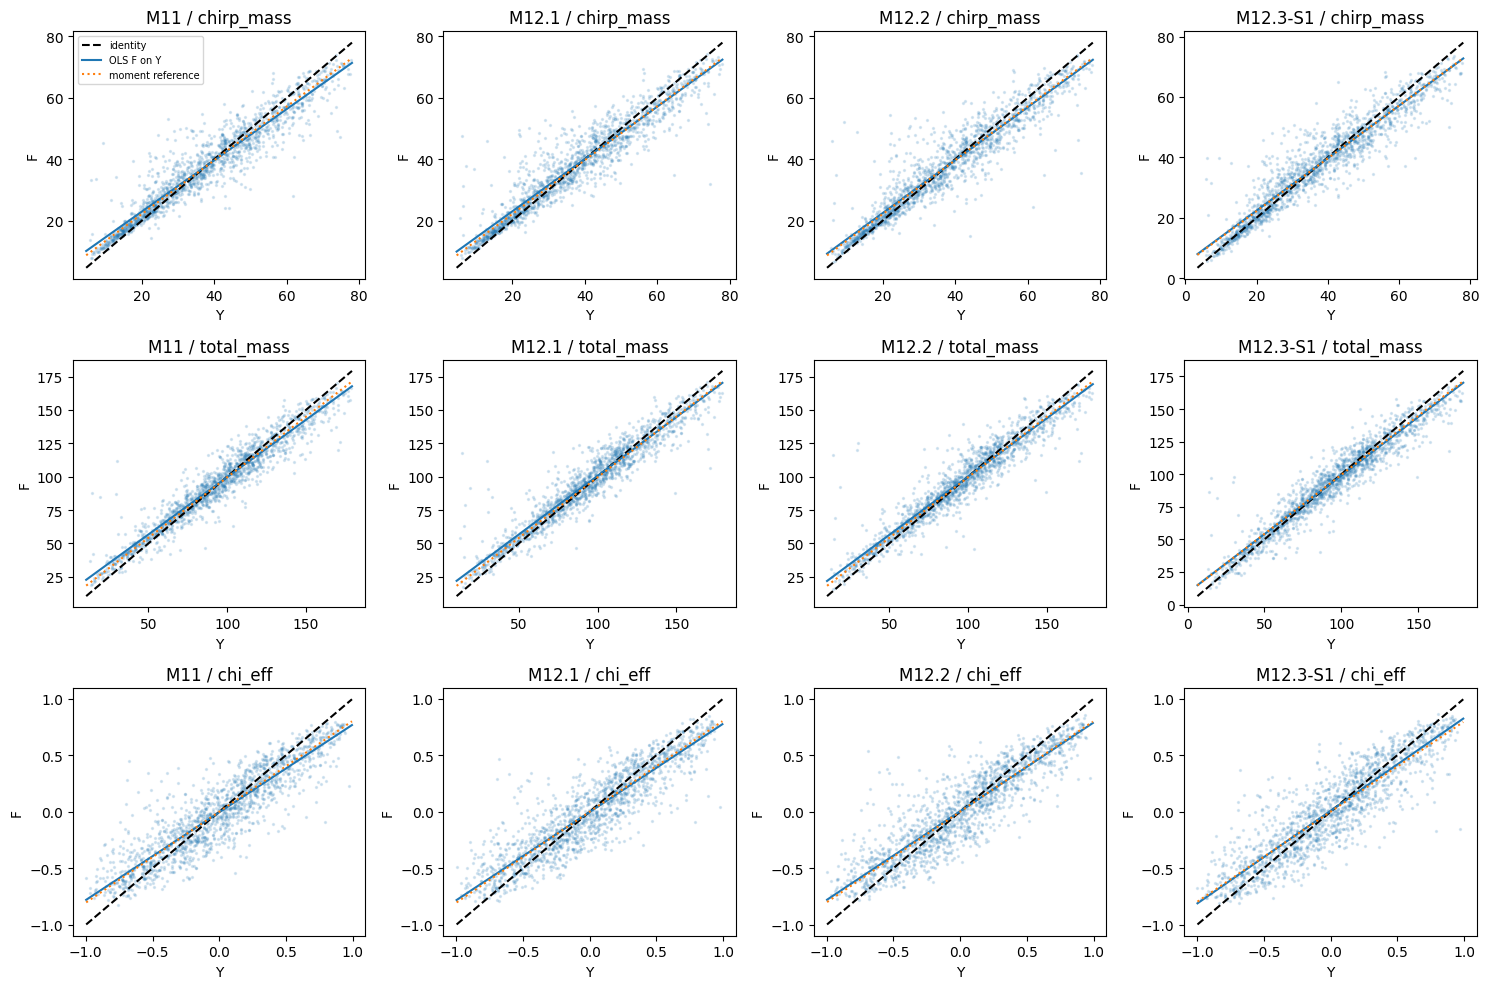

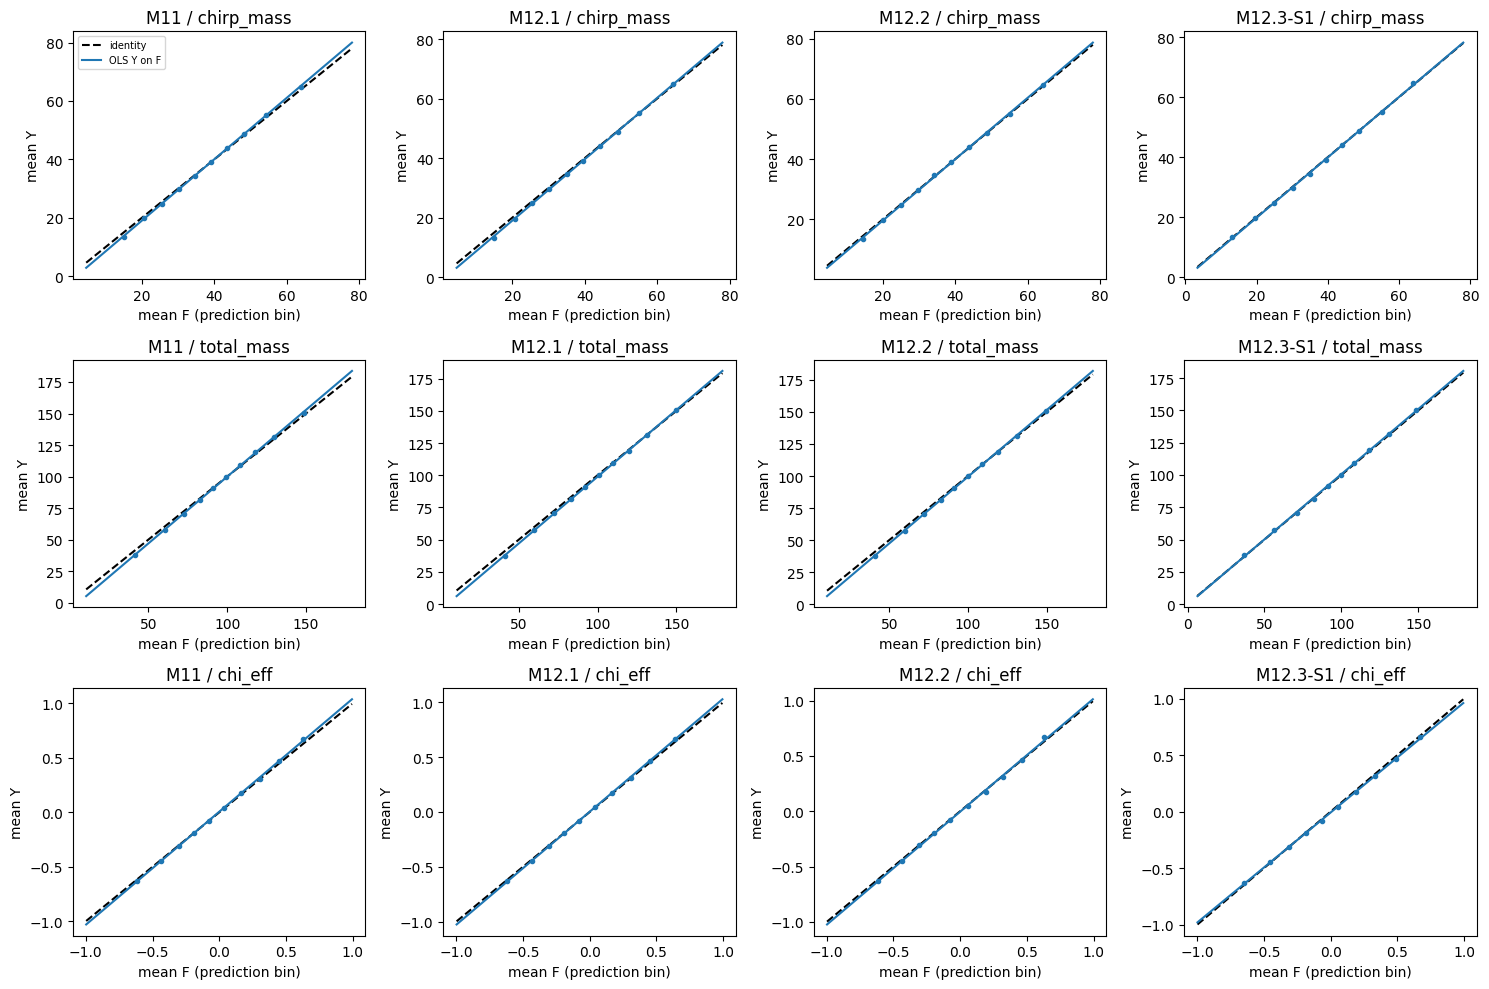

,model,label,bin,n,mean_F,mean_Y,se_Y
0,M11,chirp_mass,0,4000,14.916725,13.370649,0.062486
1,M11,chirp_mass,1,4000,20.665066,19.766068,0.067879
2,M11,chirp_mass,2,4000,25.388680,24.729060,0.075143
3,M11,chirp_mass,3,4000,30.134545,29.760816,0.088707
4,M11,chirp_mass,4,4000,34.606562,34.360529,0.093362
...,...,...,...,...,...,...,...
115,M12.3-S1,chi_eff,5,4000,0.056625,0.040648,0.003429
116,M12.3-S1,chi_eff,6,4000,0.188184,0.170176,0.003372
117,M12.3-S1,chi_eff,7,4000,0.334958,0.311695,0.003047
118,M12.3-S1,chi_eff,8,4000,0.488703,0.466703,0.002815


In [6]:
scatter_idx = np.sort(np.random.default_rng(123).choice(len(val_ids), min(1500,len(val_ids)), replace=False))
fig, axes = plt.subplots(3,4,figsize=(15,10), squeeze=False)
for j,label in enumerate(LABELS):
    for mi,model in enumerate(MODELS):
        ax = axes[j,mi]
        y, f = y_true[:,j], predictions[model][:,j]
        stats = moments(y,f)
        lo,hi = min(y.min(),f.min()), max(y.max(),f.max())
        line = np.array([lo,hi])
        ax.scatter(y[scatter_idx],f[scatter_idx],s=2,alpha=.15)
        ax.plot(line,line,"k--",label="identity")
        ax.plot(line,stats["intercept_F_on_Y"]+stats["slope_F_on_Y"]*line,label="OLS F on Y")
        ax.plot(line,y.mean()+stats["one_minus_MSE_over_varY"]*(line-y.mean()),":",label="moment reference")
        ax.set(title=model+" / "+label,xlabel="Y",ylabel="F")
axes[0,0].legend(fontsize=7)
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(3,4,figsize=(15,10), squeeze=False)
bin_rows = []
for j,label in enumerate(LABELS):
    for mi,model in enumerate(MODELS):
        ax = axes[j,mi]
        y, f = y_true[:,j], predictions[model][:,j]
        edges = np.unique(np.quantile(f,np.linspace(0,1,11)))
        assignments = np.searchsorted(edges[1:-1],f,side="right")
        for b in range(max(1,len(edges)-1)):
            mask = assignments == b
            n = int(mask.sum())
            if n < MIN_COUNT:
                bin_rows.append(dict(model=model,label=label,bin=b,n=n,mean_F=np.nan,mean_Y=np.nan,se_Y=np.nan))
                continue
            se = np.std(y[mask],ddof=0)/np.sqrt(n)
            bin_rows.append(dict(model=model,label=label,bin=b,n=n,mean_F=f[mask].mean(),mean_Y=y[mask].mean(),se_Y=se))
            ax.errorbar(f[mask].mean(),y[mask].mean(),yerr=1.96*se,fmt="o",color="C0",markersize=3)
        line = np.array([min(y.min(),f.min()),max(y.max(),f.max())])
        stats = moments(y,f)
        ax.plot(line,line,"k--",label="identity")
        ax.plot(line,stats["intercept_Y_on_F"]+stats["slope_Y_on_F"]*line,label="OLS Y on F")
        ax.set(title=model+" / "+label,xlabel="mean F (prediction bin)",ylabel="mean Y")
axes[0,0].legend(fontsize=7)
fig.tight_layout(); plt.show()
calibration_bins = pd.DataFrame(bin_rows)
display(calibration_bins)


## Scientific conclusions — M12.4.0: Statistical contraction diagnostics

### 1. Objective and scope

M12.4.0 investigated whether the prediction contraction observed in M11, M12.1, M12.2 and M12.3-S1 is compatible with necessary statistical properties of the conditional-mean estimator under squared-error loss.

The analysis reused the same 40,000 frozen G1 validation observations and existing physical-unit predictions, with verified sample-ID alignment and train-only marginal references. No additional training, inference, checkpoint selection or calibration was performed.

The primary objective was not to estimate the irreducible Bayes risk, but to identify observable departures from conditional-mean calibration and to distinguish these from regression-to-the-mean that can arise naturally under observational uncertainty.

### 2. Theoretical validation

The analytical Gaussian prior–Gaussian observation example confirmed that the optimal conditional-mean estimator may exhibit substantial forward regression-slope contraction.

For the chosen example, the optimal forward slope was approximately 0.3077, while the reverse slope of the true parameter on the prediction was exactly one.

The example also confirmed the necessary identities

$$
\mathbb E[Y-m(X)]=0,
\qquad
\operatorname{Cov}(Y,m(X))=\operatorname{Var}(m(X)),
$$

and

$$
\operatorname{MSE}(m)=
\operatorname{Var}(Y)-\operatorname{Var}(m(X)).
$$

The deliberately miscalibrated predictor violated these conditions, as expected.

This establishes the conceptual distinction between natural posterior-mean contraction and additional estimator miscalibration.

### 3. Global diagnostics

All four models exhibited forward prediction slopes below one for chirp mass, total mass and effective spin.

However, the models differed considerably in how closely they satisfied the necessary moment identities of the optimal conditional mean.

| Parameter | Model | Forward slope | Reverse slope | Delta_s |
|---|---|---:|---:|---:|
| Chirp mass | M11 | 0.8351 | 1.0508 | -0.0404 |
| Chirp mass | M12.3-S1 | 0.8688 | 1.0055 | -0.0048 |
| Total mass | M11 | 0.8593 | 1.0585 | -0.0474 |
| Total mass | M12.3-S1 | 0.8990 | 1.0087 | -0.0075 |
| Effective spin | M11 | 0.7760 | 1.0377 | -0.0280 |
| Effective spin | M12.3-S1 | 0.8202 | 0.9737 | +0.0224 |

Here,

$$
\Delta_s
=
s_{\hat Y\mid Y}-
\left(1-\frac{\operatorname{MSE}}{\operatorname{Var}(Y)}\right).
$$

The M11 baseline exhibited negative Delta_s for all three targets. The deviations were also reflected in nonzero covariance between residuals and predictions and reverse regression slopes exceeding one.

M12.3-S1 substantially reduced these global discrepancies for both mass parameters. For effective spin, however, the discrepancy changed sign, while the reverse slope fell below one.

These findings suggest that M12.3-S1 produces substantially different linear calibration behavior from M11.

They do not establish that M12.3-S1 is closer to the full Bayes-optimal conditional mean in all respects.

### 4. Calibration versus global predictive accuracy

Improved agreement with global moment identities did not necessarily yield lower MSE.

For chirp mass, MSE increased from approximately 33.9581 under M11 to 34.4742 under M12.3-S1, despite the strong reduction in the absolute value of Delta_s.

For total mass, MSE increased from 112.3106 to 112.5554, while the absolute Delta_s decreased from approximately 0.0474 to 0.0075.

For effective spin, M12.3-S1 increased the global MSE and changed the sign of the residual–prediction covariance.

These observations indicate that improving linear calibration may be accompanied by deterioration in other components of predictive error.

Therefore, neither unit forward slope nor vanishing Delta_s should be treated as a standalone optimization objective.

### 5. Residual orthogonality

The residual \(R=Y-\hat Y\) was not exactly orthogonal to the model predictions.

Normalized residual–prediction covariances, defined as

$$
\frac{\operatorname{Cov}(R,\hat Y)}
{\operatorname{Var}(Y)},
$$

were approximately:

| Parameter | M11 | M12.3-S1 |
|---|---:|---:|
| Chirp mass | +0.04038 | +0.00479 |
| Total mass | +0.04749 | +0.00776 |
| Effective spin | +0.02818 | -0.02212 |

M12.3-S1 greatly reduced the covariance residual for masses, while reversing its sign for effective spin.

Delta_s was interpreted jointly with the residual mean and covariance because

$$
\Delta_s=
\frac{\mathbb E[R]^2-\operatorname{Cov}(R,\hat Y)}
{\operatorname{Var}(Y)}.
$$

A small Delta_s can result from cancellation and is not sufficient to establish full conditional-mean calibration.

### 6. SNR dependence

The lowest analyzed network-SNR interval, 10–12.5, contained 6,757 validation observations.

In this region, forward slopes for chirp mass were lower than their global counterparts, including approximately 0.7355 for M11 and 0.7810 for M12.3-S1.

This is compatible with stronger prediction contraction when observational information is reduced.

However, SNR-conditioned results cannot by themselves distinguish intrinsic information limitations from model inadequacy, and they do not establish the irreducible Bayes risk.

The available SNR variable is a metadata-based quantity that may not be explicitly supplied to the predictor.

Controlled experiments with fixed physical parameters and multiple independent noise realizations are needed for a more direct investigation of noise-driven uncertainty.

### 7. Central, peripheral and physical-tail regions

Regional diagnostics were constructed using frozen train-only references, including marginal-peripherality thresholds and train-derived Q10/Q90 label thresholds.

These diagnostics identify where model biases and contraction differ, but the global conditional-mean identities cannot be applied naively to subsets selected using the true physical parameters.

In particular, selecting observations through Q10/Q90 changes the target distribution and can produce systematic residual behavior even for a globally optimal conditional-mean predictor.

Large regional Delta_s values, especially where within-subset target variance is small, must not be interpreted as direct measures of estimator suboptimality.

Regional RMSE, signed bias and paired differences remain useful measures of conditional predictive performance.

### 8. Prediction-conditioned calibration

Decile bins based on model predictions were used to examine the relationship between mean predicted parameters and mean observed parameters.

For an optimal conditional-mean estimator, the calibration relation

$$
\mathbb E[Y\mid \hat Y]=\hat Y
$$

must hold.

The binned analysis provides a stronger descriptive diagnostic than global linear regression alone because nonlinear calibration departures may remain even when the reverse OLS slope is close to one.

For example, the lowest chirp-mass prediction decile of M11 had mean prediction approximately 14.9167 solar masses and mean true chirp mass approximately 13.3706 solar masses.

This supports the presence of localized calibration discrepancies.

However, the current analysis does not establish that all nonlinear calibration departures are resolved under M12.3-S1. A dedicated summary of prediction-bin calibration errors and uncertainties would be needed for that claim.

### 9. Statistical limitations

Paired bootstrap uncertainty was estimated with 400 replicates and shared validation IDs across the four models.

These intervals describe sampling uncertainty conditional on the fixed checkpoints. They do not include between-training-seed variability, checkpoint-selection uncertainty or all possible dependence between simulated examples.

Subgroup comparisons are exploratory and were not corrected for multiple testing.

Satisfying the tested global moment conditions is necessary but not sufficient for Bayes optimality. Conversely, measurable departures from them indicate imperfect calibration under the evaluated distribution but do not quantify the excess Bayes risk.

The analysis cannot yet determine how much predictive error is caused by intrinsic parameter degeneracies, limited observation SNR, optimization, architecture or multitask interactions.

### 10. Scientific interpretation and next steps

**M12.4.0 identifies a measurable component of estimator miscalibration in addition to the regression-to-the-mean expected under conditional-mean prediction.**

M11 exhibits global residual–prediction associations and reverse-slope departures from the necessary conditional-mean conditions.

M12.3-S1 substantially reduces these discrepancies for both mass parameters without improving their global MSE, while its effective-spin behavior shows a change in sign of the calibration discrepancy and deterioration in global predictive accuracy.

The results support treating contraction, calibration and prediction error as distinct scientific quantities.

**The experiment does not establish proximity to the Bayes risk, prove intrinsic non-identifiability or identify a particular neural-network architecture as the cause of the remaining error.**

The next proposed investigation is **M12.4.1: multitask gradient diagnostics** using frozen checkpoints and a limited number of training minibatches, without model updates. This will evaluate whether shared-backbone gradients for chirp mass, total mass and effective spin systematically align or conflict.

A complementary future diagnostic should investigate fixed-parameter waveforms under independent noise realizations across controlled SNR conditions.

The findings will inform whether the next controlled training intervention should target multitask optimization, architecture specialization or statistical uncertainty representation.

**Status: M12.4.0 completed as a validation-only statistical diagnostic. No model selected or modified.**